# Post-processing and standard plots

This tutorial introduces the standardized post-processing interface. We run a small Vlasov–Ampère example, get its output as an autocomplete-friendly `Output`, and make the plots most commonly used to inspect a simulation.

For a production run you can skip the simulation setup and open its output folder with `struphy.Output("path/to/sim")` instead.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML

from struphy import (
    BinningPlot,
    BoundaryParameters,
    ButcherTableau,
    DerhamOptions,
    EnvironmentOptions,
    KernelDensityPlot,
    LoadingParameters,
    SavingParameters,
    Simulation,
    SortingParameters,
    Time,
    WeightsParameters,
    domains,
    equils,
    grids,
    maxwellians,
    perturbations,
)
from struphy.models import Maxwell, ViscousEulerSPH, VlasovAmpereOneSpecies

## Create a compact demonstration run

Post-processing operates on a completed run. The small setup below saves an electric field, a few marker trajectories, scalar diagnostics, and a binned $(\eta_1,v_1)$ distribution. These are the main output types handled by the plotting interface.

In [2]:
def build_model():
    model = VlasovAmpereOneSpecies(alpha=1.0, epsilon=-1.0, with_B0=False)
    model.em_fields.e_field.save_data = True
    model.em_fields.phi.save_data = True
    model.kinetic_ions.var.save_data = True

    model.propagators.push_eta.options = model.propagators.push_eta.Options()
    model.propagators.coupling_va.options = model.propagators.coupling_va.Options()
    model.initial_poisson.options = model.initial_poisson.Options(stab_mat="M0")

    binplot = BinningPlot(
        slice="e1_v1",
        n_bins=(32, 32),
        ranges=((0.0, 1.0), (-5.0, 5.0)),
    )
    model.kinetic_ions.set_markers(
        loading_params=LoadingParameters(ppc=32, seed=1234),
        weights_params=WeightsParameters(control_variate=True),
        boundary_params=BoundaryParameters(),
        sorting_params=SortingParameters(boxes_per_dim=(4, 1, 1), do_sort=True),
        saving_params=SavingParameters(n_markers=12, binning_plots=(binplot,)),
    )

    background = maxwellians.Maxwellian3D(n=(1.0, None))
    model.kinetic_ions.var.add_background(background)
    density_mode = perturbations.ModesCos(ls=(1,), amps=(1e-3,))
    model.kinetic_ions.var.add_initial_condition(maxwellians.Maxwellian3D(n=(1.0, density_mode)))

    return model


model = build_model()

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/struphy/models/species.py:215: UserWarning: Override equation parameter self.alpha =1.0
  warnings.warn(f"Override equation parameter {self.alpha =}")
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/struphy/models/species.py:222: UserWarning: Override equation parameter self.epsilon =-1.0
  warnings.warn(f"Override equation parameter {self.epsilon =}")


In [3]:
demo_tmp = tempfile.TemporaryDirectory(prefix="struphy_postprocessing_")
demo_root = demo_tmp.name

env = EnvironmentOptions(
    out_folders=demo_root,
    sim_folder="vlasov_ampere_demo",
    save_restart=False,
)
sim = Simulation(
    model=model,
    env=env,
    time_opts=Time(dt=0.05, Tend=5.0),
    domain=domains.Cuboid(r1=2 * 3.141592653589793),
    equil=equils.HomogenSlab(),
    grid=grids.TensorProductGrid(num_elements=(16, 1, 1)),
    derham_opts=DerhamOptions(degree=(2, 1, 1)),
)
out = sim.run(profiling_activated=True)
print(f"Raw output: {sim.env.path_out}")

Stabilizing Poisson solve with self.options.sigma_1 =1e-14


Time stepping:   0%|          | 0/100 [00:00<?, ?step/s]

Time stepping:   7%|▋         | 7/100 [00:00<00:01, 65.59step/s]

Time stepping:  14%|█▍        | 14/100 [00:00<00:01, 65.78step/s]

Time stepping:  21%|██        | 21/100 [00:00<00:01, 66.32step/s]

...

Time stepping:  84%|████████▍ | 84/100 [00:01<00:00, 67.83step/s]

Time stepping:  91%|█████████ | 91/100 [00:01<00:00, 67.92step/s]

Time stepping:  98%|█████████▊| 98/100 [00:01<00:00, 68.00step/s]

Time stepping: 100%|██████████| 100/100 [00:01<00:00, 67.23step/s]

  ╭─────────────────────────────────────────────────────────────────────────────────────────────╮
  │ region                                          % session             total [s]             │
  ├─────────────────────────────────────────────────────────────────────────────────────────────┤
  │ scope_profiler.session                          100.00%               1.653866              │
  │ └─ (own)                                           1.28%                 0.021212           │
  │ └─ setup: total                                    9.85%                 0.162840           │
  │ │ └─ (own)                                           0.08%                 0.001264         │
  │ │ └─ setup: allocate                                 4.72%                 0.078084         │
  │ │ │ └─ (own)                                           0.02%                 0.000378       │
  │ │ │ └─ allocate feec                                   3.01%                 0.049847       │
  │ │ │ │ └─ (own)  

## Process and load the output

`sim.run()` returns an `Output`, which is also available later as `sim.output`. Scalars are read directly from the raw output; fields and particle products need post-processing, which runs with default options the first time they are accessed.

To choose options, call `out.pproc()` first. `Output` evaluates saved FEEC fields and organizes particle diagnostics; `physical=True` additionally creates physical field components. Existing products made with the same options are reused, so re-running a cell is cheap.

Individual products are standard `xarray.DataArray` objects with named dimensions, coordinates, units, and labels. Time is in Struphy units, in which the models' analytic results are written; seconds come along as the coordinate `t_seconds`, and `out.with_time_units("physical")` gives an independent view with `t` in seconds. Arrays are loaded only when accessed. The saved configuration is available through `out.domain`, `out.model`, and `out.time_opts`; no simulation object is created.

In [4]:
out.pproc(physical=True)


Post-processing path /tmp/struphy_postprocessing_ktshefm9/vlasov_ampere_demo



Reading hdf5 data of following species:


em_fields:


  e_field: <HDF5 group "/feec/em_fields/e_field" (3 members)>


  phi: <HDF5 dataset "phi": shape (101, 20, 3, 3), type "<f8">


...

100%|██████████| 1/1 [00:00<00:00, 1290.56it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

rank = 0 ----------------------------
self._pproc_rank =0 with xp.sum(data) =np.float64(10342.800145647721) and xp.sum(data_df) =np.float64(0.31679856838042036)
self._pproc_rank =0 with xp.sum(data) =np.float64(10342.800145647721) and xp.sum(data_df) =np.float64(0.31679856838042036)
self._pproc_rank =0 done.


100%|██████████| 1/1 [00:00<00:00, 22.86it/s]

Output('/tmp/struphy_postprocessing_ktshefm9/vlasov_ampere_demo', processed=True)

Products sit on the run under the species that produced them, so VS Code and interactive shells complete them as you type: `out.kinetic_ions.e1_v1_density.f`, `out.kinetic_ions.orbits`, `out.em_fields.phi_log`. To discover the products a particular namespace contains, inspect its flat, lazy `.catalog`: `list(out.kinetic_ions.catalog)`. The grouped views `out.fields`, `out.distributions`, `out.densities` and `out.orbits` show the same products by kind. In scripts, `out.evaluate("kinetic_ions/f", dataset="e1_v1_density/f")` looks up one explicitly.

In [5]:
out.info()

Output: /tmp/struphy_postprocessing_ktshefm9/vlasov_ampere_demo

Key                                 Description                                        Load with
----------------------------------  -------------------------------------------------  ---------
electric_energy                     scalar time series (electric energy)               out.evaluate('scalars', variables='electric_energy')
em_fields/e_field                   field (e_field)                                    out.evaluate('em_fields/e_field')
em_fields/e_field_xyz               field (e_field_xyz)                                out.evaluate('em_fields/e_field_xyz')
em_fields/phi                       field (phi)                                        out.evaluate('em_fields/phi')
em_fields/phi_xyz                   field (phi_xyz)                                    out.evaluate('em_fields/phi_xyz')
kinetic_energy                      scalar time series (kinetic energy)                out.evaluate('scalars', variab

In [6]:
print(out.kinetic_ions)

ProductNamespace('kinetic_ions', products=('e1_v1_density/delta_f', 'e1_v1_density/f', 'orbits'))


### Reconstructed setup and initial conditions

`out.info()` prints every evaluable key with a short description and the exact `out.evaluate(...)` call that loads it, followed by a few hints on selecting times and coordinates. The run configuration is not part of `info()`: in `out.metadata`, serialized initial conditions live on each variable under `model → species → variables → initial_conditions`. `out.initial_conditions` gives reconstructed objects, including saved Python functions and classes; `out.model` restores them onto the model variables. Unsupported definitions remain available in `out.metadata`.

In [7]:
print("Model parameters:", out.model.params)
print("Kinetic variables:", out.model.kinetic_ions.variables)
print("Propagator options:")
for name, options in out.metadata["model"]["propagator_options"].items():
    print(f"  {name}: {options}")

saved = out.metadata["model"]["species"]["kinetic_ions"]["variables"]["var"]["initial_conditions"]
print("Initial-condition entries:", tuple(saved))
initial = out.initial_conditions["kinetic_ions"]["var"]
print("Background distribution:", initial["backgrounds"])
print("Initial distribution:", initial["initial_condition"])

Model parameters: {'base_units': BaseUnits(x=1.0, B=1.0, n=1.0, kBT=None), 'charge_number': 1, 'mass_number': 1.0, 'alpha': 1.0, 'epsilon': -1.0, 'with_B0': False}
Kinetic variables: {'var': PICVariable (Particles6D)}
Propagator options:
  push_eta: {'butcher': {'algo': 'rk4'}}
  coupling_va: {'solver': 'pcg', 'precond': 'MassMatrixPreconditioner', 'solver_params': {'tol': 1e-08, 'maxiter': 3000, 'info': False, 'recycle': True}}
Initial-condition entries: ('backgrounds', 'perturbations', 'initial_condition')
Background distribution: Maxwellian3D(
    n=(1.0, None),
    u1=(0.0, None),
    u2=(0.0, None),
    u3=(0.0, None),
    vth1=(1.0, None),
    vth2=(1.0, None),
    vth3=(1.0, None),
    uniform_on_disc=False,
)
Initial distribution: Maxwellian3D(
    n=(1.0, ModesCos(
    ls=(1,),
    ms=None,
    ns=None,
    amps=(0.001,),
    Lx=1.0,
    Ly=1.0,
    Lz=1.0,
    given_in_basis=None,
    comp=0,
    perb_domain=(None, None, None),
)),
    u1=(0.0, None),
    u2=(0.0, None),
    

The reconstructed kinetic distributions are ordinary Struphy background objects. Here we evaluate the saved equilibrium and initial distribution along $\eta_1$; their difference is the density perturbation that seeded the run.

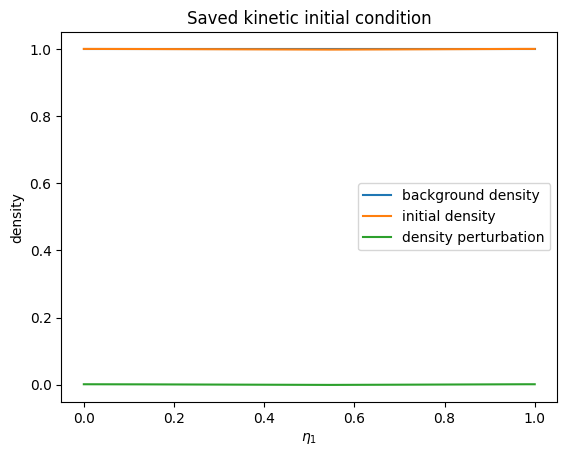

In [8]:
background = initial["backgrounds"]
initial_distribution = initial["initial_condition"]
eta1 = np.linspace(0.0, 1.0, 256)
zeros = np.zeros_like(eta1)
n_background = np.asarray(background.n(eta1, zeros, zeros))
n_initial = np.asarray(initial_distribution.n(eta1, zeros, zeros))

fig, ax = plt.subplots()
ax.plot(eta1, n_background, label="background density")
ax.plot(eta1, n_initial, label="initial density")
ax.plot(eta1, n_initial - n_background, label="density perturbation")
ax.set(xlabel=r"$\eta_1$", ylabel="density", title="Saved kinetic initial condition")
ax.legend();

In [9]:
phase_space = out.kinetic_ions.e1_v1_density.f
print(phase_space)

<xarray.DataArray 'f' (t: 101, eta1: 32, v1: 32)> Size: 827kB
[103424 values with dtype=float64]
Coordinates:
  * t          (t) float64 808B 0.0 0.05 0.1 0.15 0.2 ... 4.8 4.85 4.9 4.95 5.0
  * eta1       (eta1) float64 256B 0.01562 0.04688 0.07812 ... 0.9531 0.9844
  * v1         (v1) float64 256B -4.844 -4.531 -4.219 ... 4.219 4.531 4.844
    t_seconds  (t) float64 808B 0.0 1.668e-10 3.336e-10 ... 1.651e-08 1.668e-08
Attributes:
    label:      $f$
    long_name:  $f$
    run:        dt=0.05, algo=LieTrotter, Nel=(16, 1, 1), p=(2, 1, 1)
    run_name:   vlasov_ampere_demo


### Evaluate saved splines directly: 1-D, 2-D, and 3-D

`evaluate()` reads saved FEEC coefficients and evaluates the spline directly, without creating a post-processing field. With no `eta` arguments, it evaluates the full simulation grid at its cell centres. For cuts, pass a scalar for each direction to hold fixed; omitted directions stay on the cell centres of the simulation grid. Scalars, lists, NumPy arrays, and `range` objects can be mixed; every non-scalar input becomes a dimension of the tensor-product result. Thus one varying coordinate makes a 1-D line, two make a 2-D plane, and no coordinates makes a 3-D volume. The result is always an xarray array with logical `eta1`/`eta2`/`eta3` coordinates and mapped physical `X`/`Y`/`Z` coordinates.

A representation conversion is applied after spline evaluation. Its input is inferred from the saved FEEC space, so `representation=` specifies only the target: `"0"`, `"1"`, `"2"`, `"3"`, `"v"`, or `"norm"`. Scalars default to `"0"`; vectors default to `"norm"`.

('eta1',) (128,)


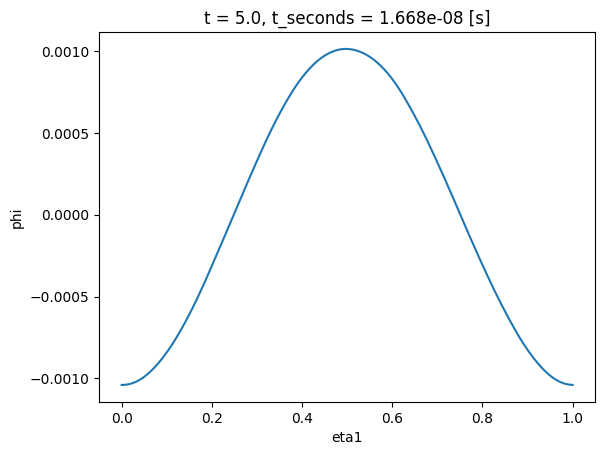

In [10]:
# 1-D: a field line at eta2 = eta3 = 0.5.
eta1_line = np.linspace(0.0, 1.0, 128)
phi_line = out.evaluate(
    "em_fields/phi",
    eta1=eta1_line,
    eta2=0.5,
    eta3=0.5,
    t=-1,
)
phi_line.plot()
print(phi_line.dims, phi_line.shape)

For a 2-D plane, vary two coordinates and hold the third fixed. This is useful for a cross-section of a 3-D field even when the simulation was run on a coarser grid: the spline is evaluated at the requested points. For a 3-D volume, vary all three coordinates. Keep volume grids modest, then take a plane or line from the labeled result for plotting or further analysis.

('eta1', 'eta2', 'eta3') (32, 16, 8)
('eta1', 'eta2', 'eta3') (16, 1, 1)


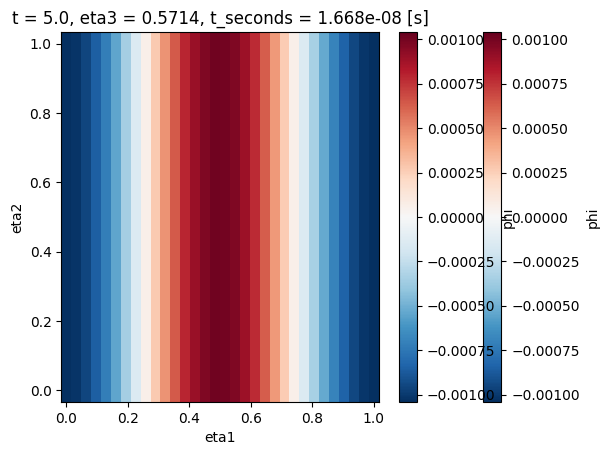

In [11]:
# 2-D: a logical eta1--eta2 plane at eta3 = 0.5.
phi_plane = out.evaluate(
    "em_fields/phi",
    eta1=np.linspace(0.0, 1.0, 64),
    eta2=np.linspace(0.0, 1.0, 48),
    eta3=0.5,
    t=-1,
)
phi_plane.plot(x="eta1", y="eta2")

# 3-D: vary all three coordinates; keep volume grids modest.
phi_volume = out.evaluate(
    "em_fields/phi",
    eta1=np.linspace(0.0, 1.0, 32),
    eta2=np.linspace(0.0, 1.0, 16),
    eta3=np.linspace(0.0, 1.0, 8),
    t=-1,
)
print(phi_volume.dims, phi_volume.shape)

# xarray plots a 2-D slice of the volume; choose the mid-plane by coordinate index.
phi_volume.isel(eta3=phi_volume.sizes["eta3"] // 2).plot(x="eta1", y="eta2")

# Without eta arguments the spline is evaluated at the cell centres of the simulation grid,
# here 16 x 1 x 1 cells, so this run's grid gives a line along eta1.
phi_grid = out.evaluate("em_fields/phi", t=-1)
print(phi_grid.dims, phi_grid.shape)

### Inspecting `out` itself

Most of what `out` exposes is generated on demand (`__getattr__`, cached properties), so `vars(out)` only shows a handful of private cache slots, not the products or methods. Use `dir(out)` for the flat list IPython's own tab-completion relies on, and `out.info()` for the full product tree. The same applies one level down: `out.model` is not a generic stub but the concrete model class of the run (`VlasovAmpereOneSpecies` here), so `dir(out.model)` and `print(out.model)` already show that model's own parameters directly — no separate `OutputVlasovAmpereOneSpecies`-style class is needed.

In [12]:
print("vars(out):", vars(out))  # only private cache slots

vars(out): {'path_out': PosixPath('/tmp/struphy_postprocessing_ktshefm9/vlasov_ampere_demo'), '_time_units': 'normalized', 'comm': SerialComm(COMM_WORLD), '_time': None, '_grids_log': None, '_grids_phy': None, '_scalars': <xarray.Dataset> Size: 4kB
Dimensions:          (t: 101)
Coordinates:
  * t                (t) float64 808B 0.0 0.05 0.1 0.15 ... 4.85 4.9 4.95 5.0
    t_seconds        (t) float64 808B 0.0 1.668e-10 ... 1.651e-08 1.668e-08
Data variables:
    electric_energy  (t) float64 808B 1.662e-06 1.651e-06 ... 1.494e-07
    kinetic_energy   (t) float64 808B 0.0003264 0.0003055 ... -0.0003428
    total_energy     (t) float64 808B 0.0003281 0.0003071 ... -0.0003426, '_products': {'fields': <struphy.post_processing.output.ProductMapping object at 0x7f521f7e5750>, 'distributions': <struphy.post_processing.output.ProductMapping object at 0x7f521f4e34c0>, 'densities': <struphy.post_processing.output.ProductMapping object at 0x7f521f4e3280>, 'orbits': <struphy.post_processing.output.P

In [13]:
print("dir(out):", [name for name in dir(out) if not name.startswith("_")])

dir(out): ['analysis', 'catalog', 'clear_cache', 'close', 'comm', 'compare', 'densities', 'density_catalog', 'derham_opts', 'distribution_catalog', 'distributions', 'domain', 'em_fields', 'equil', 'evaluate', 'field_basis', 'field_catalog', 'field_form', 'fields', 'grid', 'grids_log', 'grids_phy', 'info', 'initial_conditions', 'is_processed', 'iter_spline_coefficients', 'keys', 'kinetic_ions', 'label', 'metadata', 'model', 'mpi_ranks', 'orbit_catalog', 'orbits', 'path_out', 'path_pproc', 'plot', 'pproc', 'profile', 'provenance', 'report', 'save_scalars', 'scalars', 'seconds_per_time', 'species_catalog', 'spline_fields', 'standard_snapshots', 'time', 'time_opts', 'time_scale', 'time_unit', 'time_units', 'to_si', 'tree', 'units', 'with_physical_coords', 'with_time_units', 'xarray']


In [14]:
print(out.model)  # the concrete model class, with its own parameters

VlasovAmpereOneSpecies(
    base_units=BaseUnits(x=1.0, B=1.0, n=1.0, kBT=None),
    charge_number=1,
    mass_number=1.0,
    alpha=1.0,
    epsilon=-1.0,
    with_B0=False,
)


In [15]:
print("dir(out.model):", [name for name in dir(out.model) if not name.startswith("_")][:15])

dir(out.model): ['EMFields', 'KineticIons', 'Propagators', 'base_units', 'bulk_species', 'cannot_be_used_for', 'cannot_be_used_for_html', 'cannot_be_used_for_latex', 'cannot_be_used_for_markdown', 'clone_config', 'create_doc', 'diagnostic_species', 'discretization', 'discretization_html', 'discretization_latex']


### Products are xarray arrays

A product is an `xarray.DataArray`, so xarray's own plotting already draws it, with the labels and units Struphy stored:

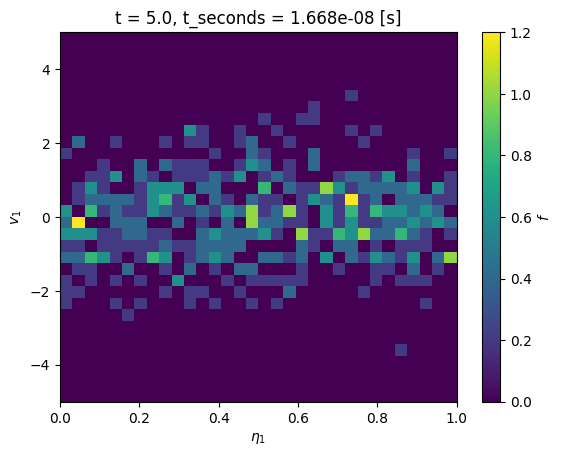

In [16]:
phase_space.isel(t=-1).plot(x="eta1", y="v1")

Use xarray's plotting methods for ordinary one- and two-dimensional output. Select a saved time or spatial slice with `.isel()` or `.sel()` first, then call `.plot()` or `.plot.line()`.

## Scalar overview and time series

Field and particle products are xarray `DataArray` objects; `out.evaluate("scalars")` returns an xarray `Dataset`. `out.evaluate("kinetic_ions/f", dataset="e1_v1_density/f")` looks a product up by name, which suits scripts and loops; attribute access is convenient interactively.

Call `.plot()` for a scalar time series. Use a Matplotlib axes when combining several series or setting plot options.

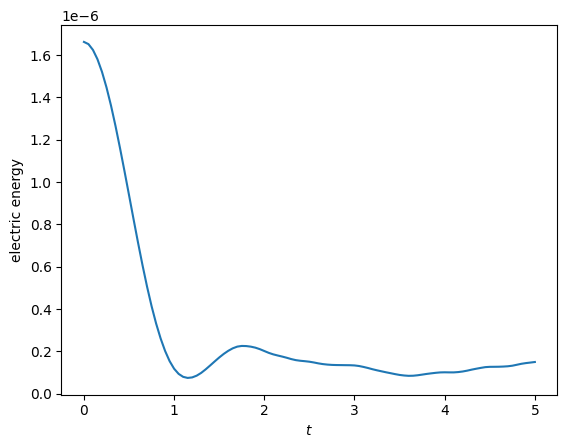

In [17]:
out.scalars.electric_energy.plot.line(x="t")

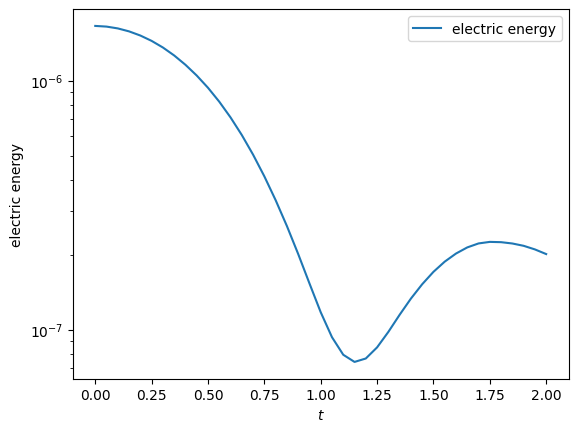

In [18]:
t_fit = 2.0  # Struphy time units, like every time coordinate of this run
energy = out.scalars.electric_energy.sel(t=slice(0.0, t_fit))
fig, ax = plt.subplots()
energy.plot.line(ax=ax, label="electric energy")
ax.set_yscale("log")
ax.legend()

## Two-dimensional data

Choose the displayed dimensions with `x` and `y`, and pick one value for every other dimension by naming it: `t="last"` (or `"first"`), `t=-1` for a position, and `t=0.35` for the nearest coordinate value. Arrays can also be sliced beforehand with xarray's `.isel()` and `.sel()`. `coords="physical"` draws on the mapped coordinates instead of the logical ones.

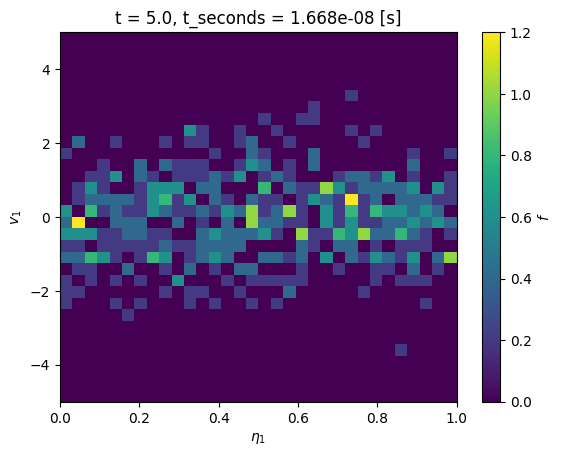

In [19]:
phase_space.isel(t=-1).plot(x="eta1", y="v1")

For a compact view of the evolution, select saved times and use xarray faceting.

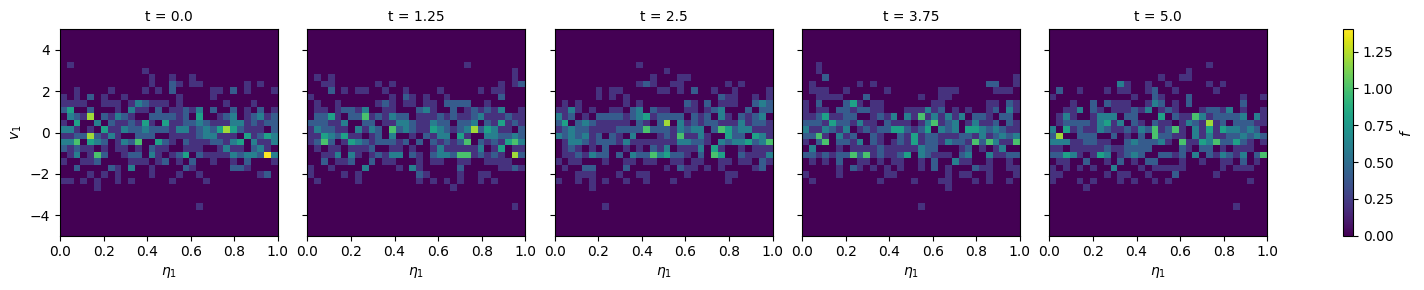

In [20]:
phase_space.isel(t=np.linspace(0, phase_space.sizes["t"] - 1, 5, dtype=int)).plot(x="eta1", y="v1", col="t", col_wrap=5)

## Selecting saved snapshots

Use `.isel()` for index-based selection and `.sel()` for coordinate-based selection. This keeps selection explicit and works with every xarray operation.

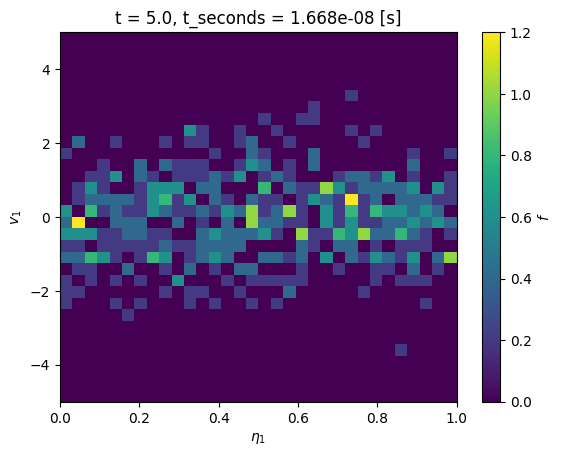

In [21]:
final_phase_space = phase_space.isel(t=-1)
final_phase_space.plot(x="eta1", y="v1")

Saved marker orbits sit under their species as an `xarray.Dataset` with one `(t, marker)` variable per quantity (`x`, `y`, `z`, velocities, `weight`); each variable's `description` attribute says what it is. Select one marker and plot its positions over time.

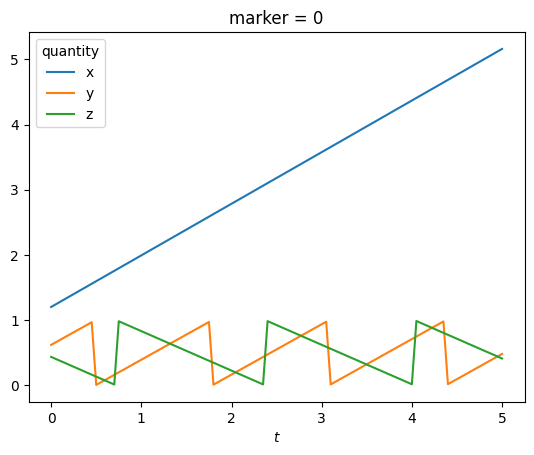

In [22]:
orbit = out.kinetic_ions.orbits.isel(marker=0)
orbit[["x", "y", "z"]].to_dataarray("quantity").plot.line(x="t", hue="quantity")

A small collection of explicit snapshots is often more useful in a reproducible notebook than an interactive widget or animation.

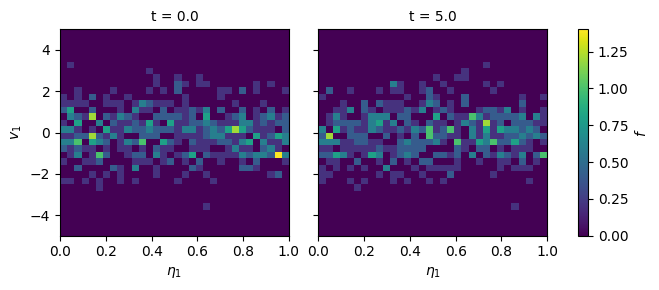

In [23]:
phase_space.isel(t=[0, -1]).plot(x="eta1", y="v1", col="t")

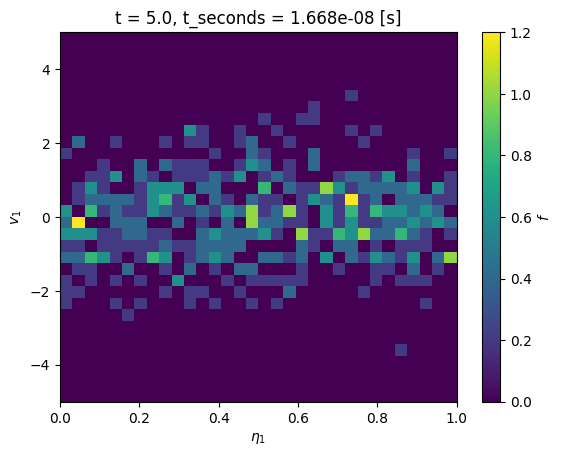

In [24]:
fig, ax = plt.subplots()
phase_space.isel(t=-1).plot(ax=ax, x="eta1", y="v1")
fig.savefig(os.path.join(demo_root, "phase_space_final.png"), bbox_inches="tight")

The reconstructed equilibrium is available directly on the output handle for inspection and for model-specific analysis.

In [25]:
print(out.equil)

HomogenSlab(
    B0x=0.0,
    B0y=0.0,
    B0z=1.0,
    beta=0.1,
    n0=1.0,
)


## Derived quantities

xarray arithmetic computes derived quantities without special APIs. For example, subtract the first sample to obtain a drift and divide by it to obtain a relative error.

largest drift of the total energy: 6.707e-04


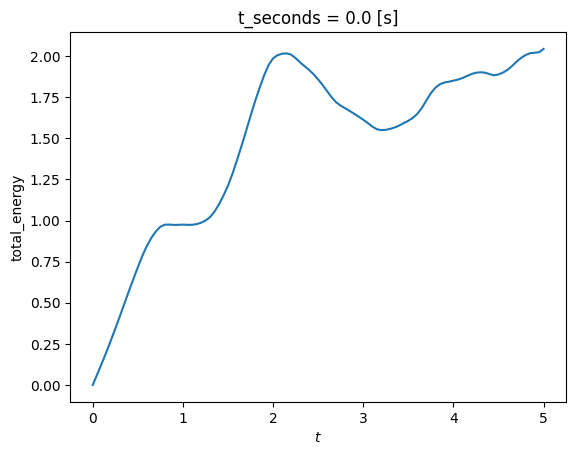

In [26]:
total_energy = out.scalars.total_energy
energy_drift = total_energy - total_energy.isel(t=0)
energy_error = abs(energy_drift) / abs(total_energy.isel(t=0))
print(f"largest drift of the total energy: {abs(energy_drift).max().item():.3e}")

energy_error.plot.line(x="t")

For custom diagnostics, first select the labeled subset needed for the calculation. Here a space-time field line is retained as an xarray object, ready for NumPy, SciPy, or another analysis package.

In [27]:
space_time_line = out.evaluate("em_fields/phi", eta1=np.linspace(0.0, 1.0, 64), eta2=0.5, eta3=0.5)
print(space_time_line.dims, space_time_line.shape)

('t', 'eta1') (101, 64)


## Reducing distribution functions

A binned distribution usually has more dimensions than the question needs. Xarray reductions retain the remaining named dimensions, so averaging over `e1`, `e2` and `e3` turns the $(\eta_1, v_1)$ product into $f(v_1, t)$. The mean is uniform in logical coordinates, which is a volume average on a Cartesian domain.

('t', 'v1')


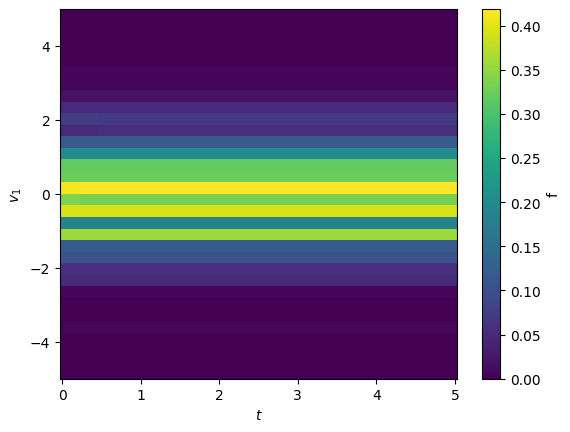

In [28]:
# average over whichever logical space directions the binning kept
spatial = [dim for dim in ("eta1", "eta2", "eta3") if dim in phase_space.dims]
f_of_v = phase_space.mean(spatial)
print(f_of_v.dims)
f_of_v.plot(x="t", y="v1")

Velocity moments are weighted xarray reductions. The bin widths and velocity coordinate remain labeled, making the density, mean velocity, and variance explicit.

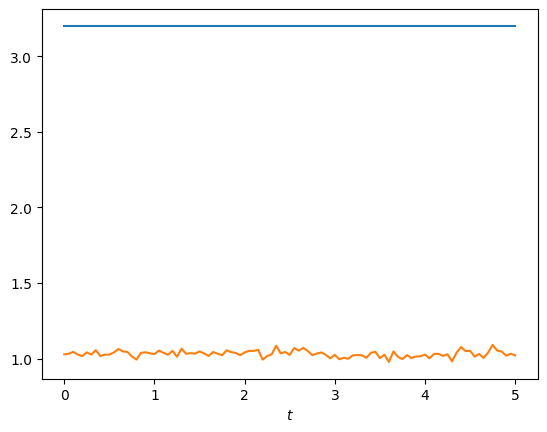

In [29]:
dv1 = phase_space.v1.differentiate("v1")
density = (phase_space * dv1).sum("v1")
mean_v1 = (phase_space * phase_space.v1 * dv1).sum("v1") / density
variance_v1 = (phase_space * (phase_space.v1 - mean_v1) ** 2 * dv1).sum("v1") / density
mean_density = density.mean(spatial)
mean_density.plot.line(x="t")
variance_v1.mean(spatial).plot.line(x="t")

## Physical units

Products are in the normalization of the model. `out.units` holds the units of that normalization and `out.to_si(product)` converts a product: the time coordinate to seconds, the mapped coordinates `X`, `Y`, `Z` to meters and the velocities `v1`, `v2`, `v3` to m/s. The values are converted only when `unit=` names the unit the variable was normalized with (`"x"`, `"B"`, `"n"`, `"v"`, `"t"`, `"p"`, `"rho"`, `"j"` or `"kBT"`), or a number for a composite unit together with its `label`, because a product does not record which unit its variable uses. The original product is not modified.

1 length unit = 1.0 m, 1 velocity unit = 2.998e+08 m/s, 1 time unit = 3.336e-09 s
m/s s


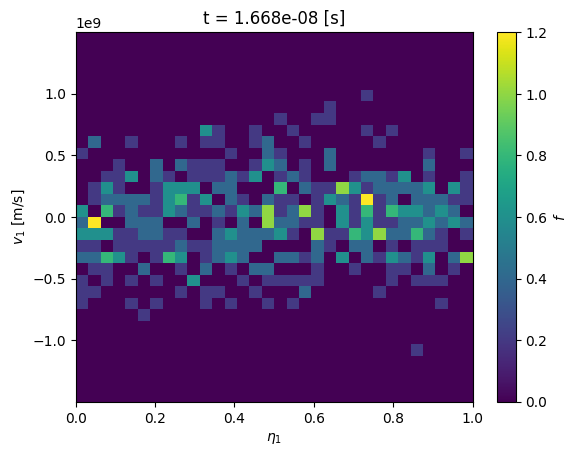

In [30]:
print(f"1 length unit = {out.units.x} m, 1 velocity unit = {out.units.v:.4g} m/s, 1 time unit = {out.units.t:.4g} s")

phase_space_si = out.to_si(phase_space)
print(phase_space_si.v1.attrs["units"], phase_space_si.t.attrs["units"])
phase_space_si.isel(t=-1).plot(x="eta1", y="v1")

## Save standard output

Products are xarray objects, so figures are saved with Matplotlib's `plt.savefig(path)` and arrays with xarray's own writers, for example `phi.to_netcdf(path)`. For a compact record of the run, `out.report()` writes the full scalar history as `scalars.csv` and a report listing the run metadata, every available product, and the dimensions and units of any products passed with `products=`. By default the files go to `post_processing/report/`; `format` is `"markdown"` or `"html"`, and the return value is the path of the report file.

In [31]:
report = out.report(products=["em_fields/phi"], format="html")
print("Wrote:")
for path in (report, os.path.join(os.path.dirname(report), "scalars.csv")):
    print(" ", os.path.relpath(path, out.path_out))

Wrote:
  post_processing/report/report.html
  post_processing/report/scalars.csv


## Comparing runs

Time series accept arrays of other simulations, so comparing runs needs nothing special. Series are labelled by the run they come from, and the runs may have different time grids.

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/struphy/models/species.py:215: UserWarning: Override equation parameter self.alpha =1.0
  warnings.warn(f"Override equation parameter {self.alpha =}")
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/struphy/models/species.py:222: UserWarning: Override equation parameter self.epsilon =-1.0
  warnings.warn(f"Override equation parameter {self.epsilon =}")
Stabilizing Poisson solve with self.options.sigma_1 =1e-14


Time stepping:   0%|          | 0/50 [00:00<?, ?step/s]

Time stepping:  14%|█▍        | 7/50 [00:00<00:00, 67.02step/s]

Time stepping:  28%|██▊       | 14/50 [00:00<00:00, 67.83step/s]

Time stepping:  42%|████▏     | 21/50 [00:00<00:00, 68.05step/s]

...

Time stepping:  70%|███████   | 35/50 [00:00<00:00, 68.25step/s]

Time stepping:  84%|████████▍ | 42/50 [00:00<00:00, 67.19step/s]

Time stepping:  98%|█████████▊| 49/50 [00:00<00:00, 66.72step/s]

Time stepping: 100%|██████████| 50/50 [00:00<00:00, 67.00step/s]


  ╭─────────────────────────────────────────────────────────────────────────────────────────────╮
  │ region                                          % session             total [s]             │
  ├─────────────────────────────────────────────────────────────────────────────────────────────┤
  │ scope_profiler.session                          100.00%               0.909113              │
  │ └─ (own)                                           1.32%                 0.011983           │
  │ └─ setup: total                                    17.71%                0.160989           │
  │ │ └─ (own)                                           0.14%                 0.001298         │
  │ │ └─ setup: allocate                                 8.23%                 0.074859         │
  │ │ │ └─ (own)                                           0.03%                 0.000294       │
  │ │ │ └─ allocate feec                                   5.27%                 0.047871       │
  │ │ │ │ └─ (own) 

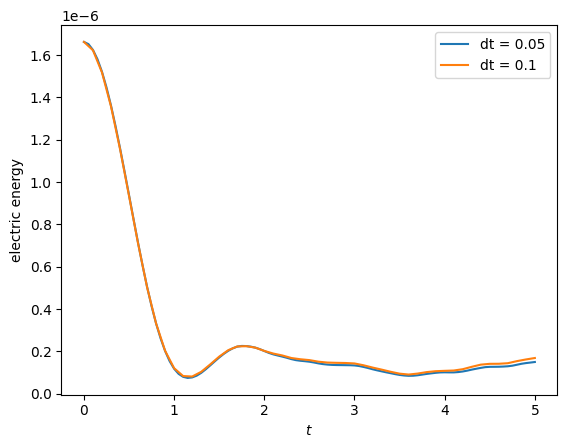

In [32]:
sim_coarse = Simulation(
    model=build_model(),
    env=EnvironmentOptions(out_folders=demo_root, sim_folder="vlasov_ampere_coarse", save_restart=False),
    time_opts=Time(dt=0.1, Tend=5.0),
    domain=domains.Cuboid(r1=2 * 3.141592653589793),
    equil=equils.HomogenSlab(),
    grid=grids.TensorProductGrid(num_elements=(16, 1, 1)),
    derham_opts=DerhamOptions(degree=(2, 1, 1)),
)
out_coarse = sim_coarse.run(profiling_activated=True)

fig, ax = plt.subplots()
out.scalars.electric_energy.plot.line(ax=ax, label="dt = 0.05")
out_coarse.scalars.electric_energy.plot.line(ax=ax, label="dt = 0.1")
ax.legend()

## Profiling

A run started with `sim.run(profiling_activated=True)` records how long each region of the code takes, and `out.profile` reads that record back. Regions are the setup steps, every propagator (`prop: ...`), pusher, accumulation, compiled kernel (`kernel: ...`) and linear solve. Regions nest, so a region's time includes the regions it calls and the times of different regions must not be added up. `summary()` returns a dataset along the dimension `region`, sorted by total time; `table()` prints it. Filter with `prefix` and limit with `top`.

In [33]:
print(out.profile.table(top=8))

kernels = out.profile.summary(prefix="kernel:")
print(kernels.total_time.to_series())

Profile: dt=0.05, algo=LieTrotter, Nel=(16, 1, 1), p=(2, 1, 1) (1 rank(s), 1.654 s)

Region                         Calls   Total [s]   Mean [ms]    Share
--------------------------  --------  ----------  ----------  -------
scope_profiler.session             1       1.654    1653.866   100.0%
model.integrate                  100       0.708       7.082    42.8%
save data                        101       0.682       6.749    41.2%
prop: VlasovAmpereCoupling       100       0.643       6.427    38.9%
solve: SchurSolver               100       0.401       4.007    24.2%
setup: total                       1       0.163     162.840     9.8%
accum: vlasov_maxwell            100       0.161       1.613     9.8%
diagnostics                      100       0.080       0.799     4.8%
region
kernel: vlasov_maxwell          0.074597
kernel: push_eta_stage          0.023113
kernel: push_v_with_efield      0.019467
kernel: charge_density_0form    0.000149
Name: total_time, dtype: float64


`compare()` puts the same statistic of several runs side by side, with runs whose region is missing as NaN. Here the two runs of the previous section differ only in the time step, so the number of calls per propagator halves for `dt = 0.1`.

In [34]:
calls = out.profile.compare(out_coarse, metric="calls", prefix="prop:")
print(calls)

<xarray.DataArray 'calls' (run: 2, region: 2)> Size: 32B
array([[100., 100.],
       [ 50.,  50.]])
Coordinates:
  * region   (region) <U26 208B 'prop: VlasovAmpereCoupling' 'prop: PushEta'
  * run      (run) <U53 424B 'dt=0.05, algo=LieTrotter, Nel=(16, 1, 1), p=(2,...
Attributes:
    label:    calls per rank


## Other models

The interface is the same for every model; only the products differ. Two more short runs show the two product types the Vlasov–Ampère demo does not have: SPH densities, and vector fields on a mapped domain.

### SPH densities

A standing sound wave discretized with SPH markers. `KernelDensityPlot` reconstructs the density on a grid, which appears under `out.densities`, while `BinningPlot` produces the binned quantities under `out.distributions`.

In [35]:
sph_model = ViscousEulerSPH(with_B0=False, with_viscosity=False)
sph_model.propagators.push_eta.options = sph_model.propagators.push_eta.Options(
    butcher=ButcherTableau(algo="forward_euler"),
)
sph_model.propagators.push_sph_p.options = sph_model.propagators.push_sph_p.Options(kernel_type="gaussian_1d")
sph_model.euler_fluid.set_markers(
    loading_params=LoadingParameters(ppb=8, loading="tesselation"),
    weights_params=WeightsParameters(),
    boundary_params=BoundaryParameters(),
    sorting_params=SortingParameters(boxes_per_dim=(12, 1, 1), dims_mask=(True, False, False)),
    saving_params=SavingParameters(
        binning_plots=(BinningPlot(slice="e1", n_bins=(32,), ranges=(0.0, 1.0)),),
        kernel_density_plots=(KernelDensityPlot(pts_e1=41, pts_e2=1),),
    ),
)
sph_model.euler_fluid.var.add_background(equils.ConstantVelocity())
sph_model.euler_fluid.var.add_perturbation(del_n=perturbations.ModesSin(ls=(1,), amps=(1.0e-2,)))

sph = Simulation(
    model=sph_model,
    env=EnvironmentOptions(out_folders=demo_root, sim_folder="sph_soundwave", save_restart=False),
    time_opts=Time(dt=0.03125, Tend=2.5, split_algo="Strang"),
    domain=domains.Cuboid(r1=2.5),
    grid=None,
    derham_opts=None,
)
out_sph = sph.run()

print("densities:", tuple(out_sph.density_catalog))
print("binned:", tuple(out_sph.distribution_catalog))

Time stepping:   0%|          | 0/80 [00:00<?, ?step/s]

Time stepping:  19%|█▉        | 15/80 [00:00<00:00, 140.83step/s]

Time stepping:  38%|███▊      | 30/80 [00:00<00:00, 139.82step/s]

Time stepping:  55%|█████▌    | 44/80 [00:00<00:00, 139.44step/s]

Time stepping:  72%|███████▎  | 58/80 [00:00<00:00, 139.57step/s]

...

100%|██████████| 1/1 [00:00<00:00, 31.62it/s]

Evaluation of sph density for euler_fluid


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 17.41it/s]

densities: ('euler_fluid/view_0/n',)
binned: ('euler_fluid/e1_density/f', 'euler_fluid/e1_density/delta_f')


For a one-dimensional run, the clearest picture is a space-time map: the sweep dimension `t` may be used as a display axis.

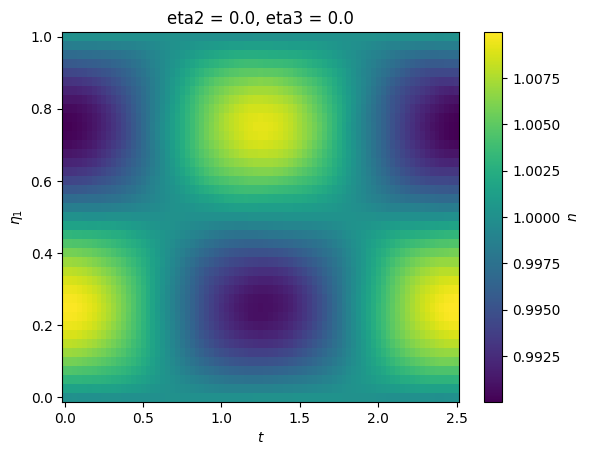

In [36]:
density = out_sph.euler_fluid.view_0.n.isel(eta2=0, eta3=0)
density.plot(x="t", y="eta1")

Products are plain `xarray.DataArray` objects, so anything xarray can do works directly, for example profiles at selected times:

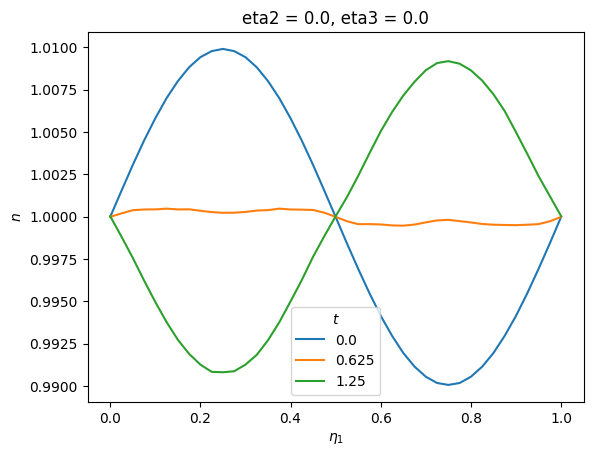

In [37]:
density.isel(t=[0, len(density.t) // 4, len(density.t) // 2]).plot.line(x="eta1")

### Vector fields on a mapped domain

A coaxial waveguide mode of the Maxwell model, on an annulus. With `physical=True` the post-processing also computes the Cartesian field components (`*_xyz`), and `coords="physical"` draws them on the mapped grid, with the plane chosen by `plane`.

In [38]:
a1, a2 = 2.326744, 3.686839

maxwell_model = Maxwell()
maxwell_model.propagators.maxwell.options = maxwell_model.propagators.maxwell.Options(algo="implicit")
maxwell_model.em_fields.e_field.add_perturbation(perturbations.CoaxialWaveguideElectric_r(m=3, a1=a1, a2=a2))
maxwell_model.em_fields.e_field.add_perturbation(perturbations.CoaxialWaveguideElectric_theta(m=3, a1=a1, a2=a2))
maxwell_model.em_fields.b_field.add_perturbation(perturbations.CoaxialWaveguideMagnetic(m=3, a1=a1, a2=a2))

coaxial = Simulation(
    model=maxwell_model,
    env=EnvironmentOptions(out_folders=demo_root, sim_folder="coaxial", save_restart=False),
    time_opts=Time(dt=0.05, Tend=2.0),
    domain=domains.HollowCylinder(a1=a1, a2=a2, Lz=2.0),
    equil=equils.HomogenSlab(),
    grid=grids.TensorProductGrid(num_elements=(24, 48, 1)),
    derham_opts=DerhamOptions(degree=(2, 2, 1), bcs=(("dirichlet", "dirichlet"), None, None)),
)
out_coaxial = coaxial.run()
out_coaxial.pproc(physical=True)

print("fields:", tuple(out_coaxial.field_catalog))
print("dimensions:", out_coaxial.em_fields.b_field_xyz.dims)

Time stepping:   0%|          | 0/40 [00:00<?, ?step/s]

Time stepping:  10%|█         | 4/40 [00:00<00:01, 33.12step/s]

Time stepping:  20%|██        | 8/40 [00:00<00:00, 33.56step/s]

Time stepping:  30%|███       | 12/40 [00:00<00:00, 32.49step/s]

Time stepping:  40%|████      | 16/40 [00:00<00:00, 32.63step/s]

...

 34%|███▍      | 14/41 [00:00<00:00, 134.93it/s]

 68%|██████▊   | 28/41 [00:00<00:00, 134.00it/s]

100%|██████████| 41/41 [00:00<00:00, 133.59it/s]


No kinetic data found in hdf5 file, skipping post-processing of kinetic data.


fields: ('em_fields/b_field', 'em_fields/b_field_xyz', 'em_fields/e_field', 'em_fields/e_field_xyz')
dimensions: ('t', 'component', 'eta1', 'eta2', 'eta3')


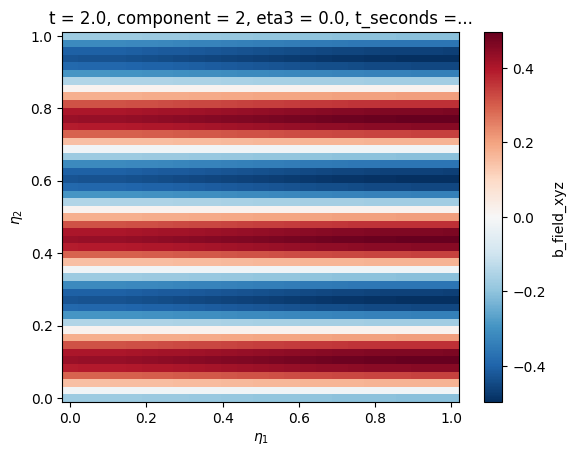

In [39]:
out_coaxial.em_fields.b_field_xyz.isel(t=-1, component=2, eta3=0).plot(x="eta1", y="eta2")

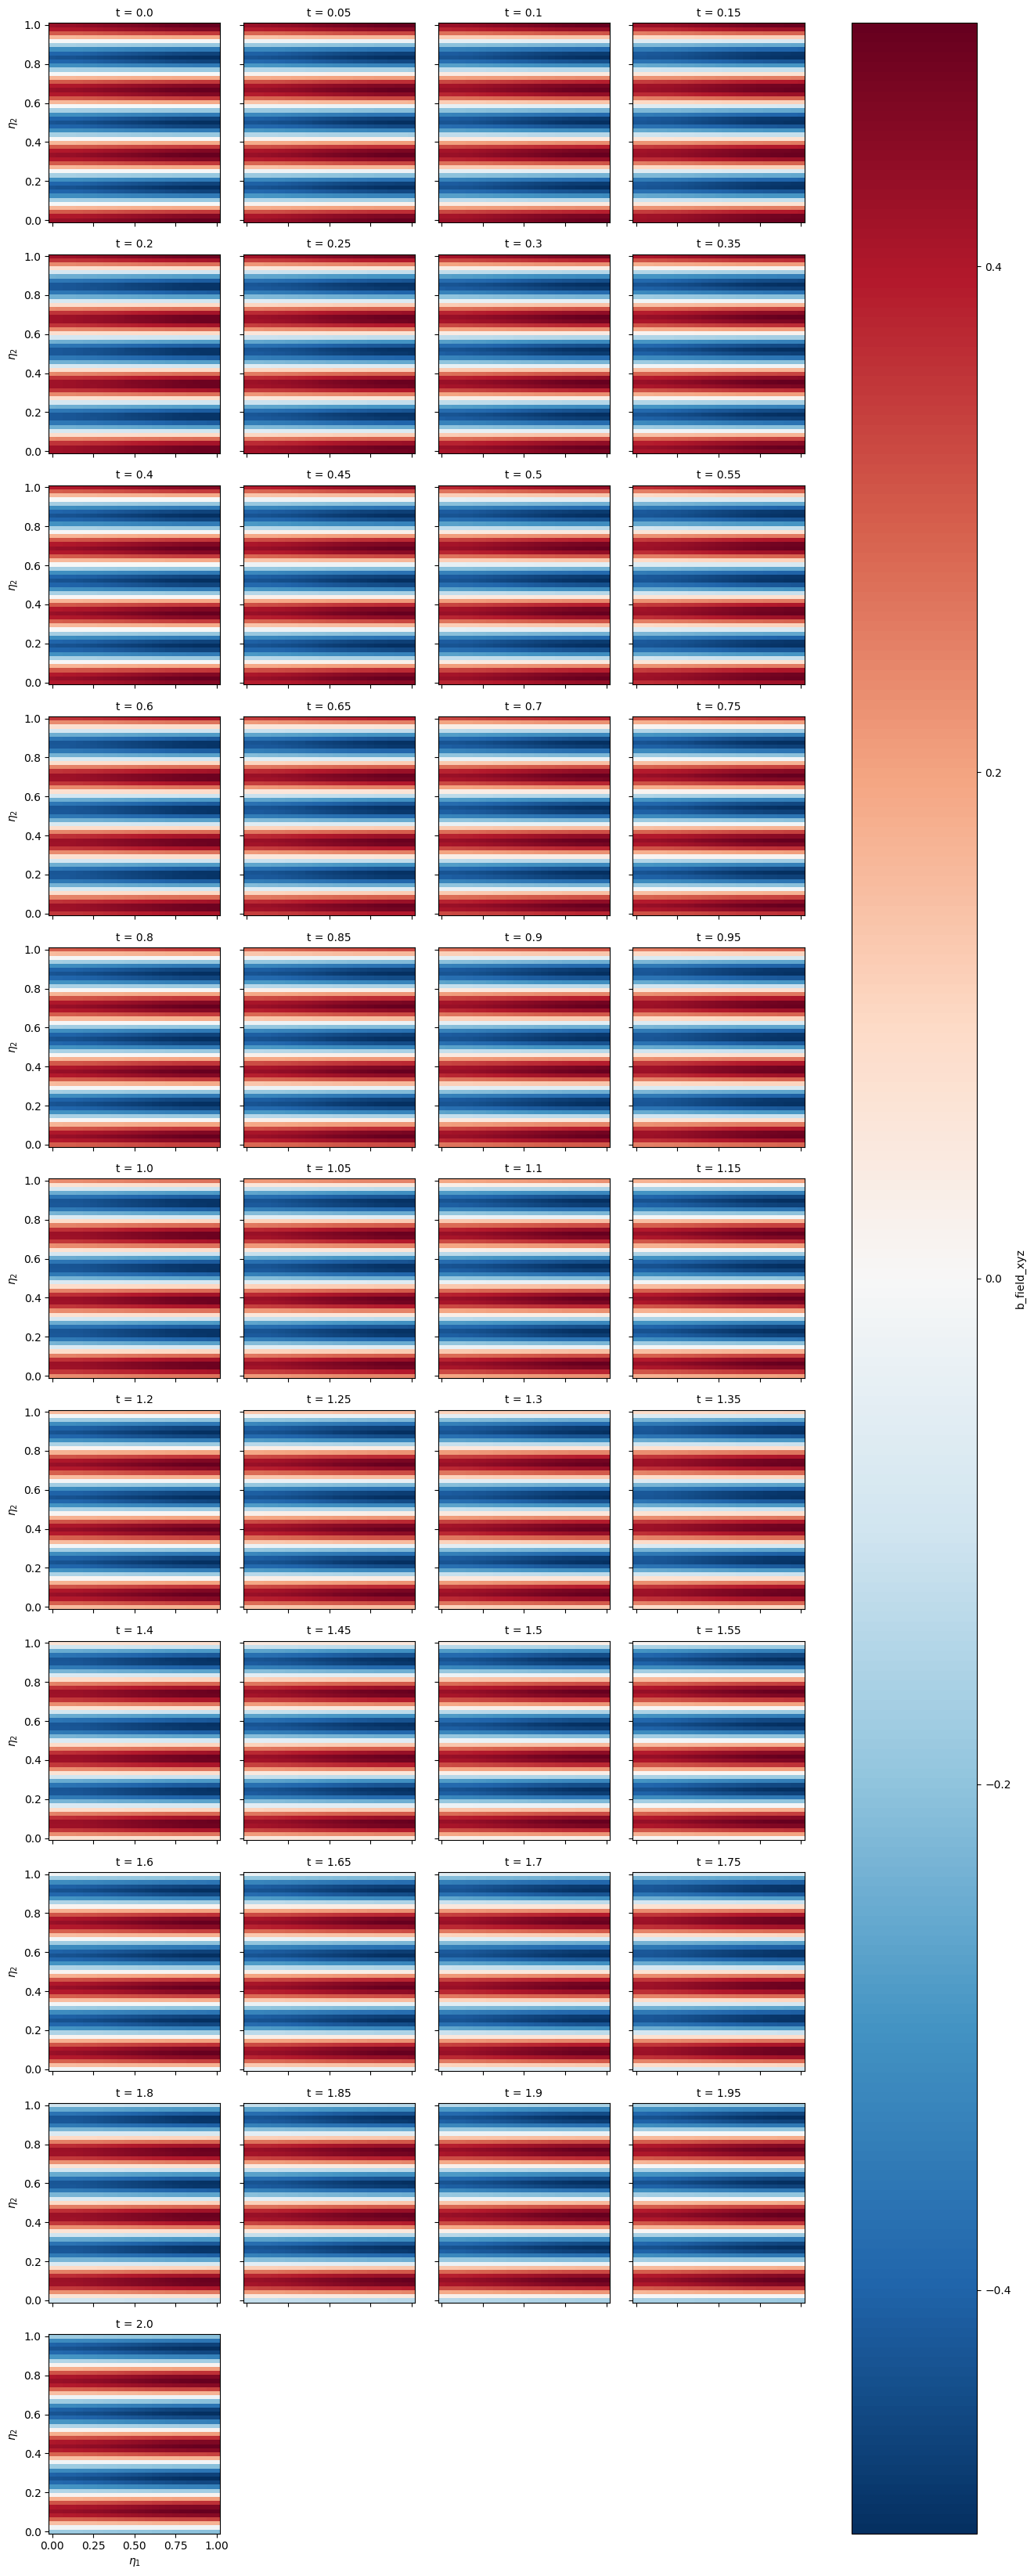

In [40]:
out_coaxial.em_fields.b_field_xyz.isel(component=2, eta3=0).plot(x="eta1", y="eta2", col="t", col_wrap=4)

### Representation conversion on a torus

A toroidal map makes the distinction between FEEC representations visible. The saved electric field is an H(curl) 1-form, so its source representation is inferred as `1`. We evaluate one poloidal line directly from saved spline coefficients, then request its native 1-form, normalized-vector, and Cartesian-vector representations. These differ away from a Cartesian map because the metric factors vary around the torus.

In [41]:
torus_model = Maxwell()
torus_model.em_fields.e_field.save_data = True
torus_model.em_fields.e_field.add_perturbation(perturbations.ModesCos(ms=(1,), amps=(0.1,), given_in_basis="1", comp=1))

torus = Simulation(
    model=torus_model,
    env=EnvironmentOptions(out_folders=demo_root, sim_folder="representation_torus", save_restart=False),
    time_opts=Time(dt=0.05, Tend=0.05),
    domain=domains.HollowTorus(a1=0.2, a2=0.4, R0=1.0, tor_period=1),
    equil=equils.HomogenSlab(),
    grid=grids.TensorProductGrid(num_elements=(6, 12, 2)),
    derham_opts=DerhamOptions(degree=(2, 2, 2), bcs=(("dirichlet", "dirichlet"), None, None)),
)
out_torus = torus.run()

Time stepping:   0%|          | 0/1 [00:00<?, ?step/s]

Time stepping: 100%|██████████| 1/1 [00:00<00:00, 16.91step/s]

1-form <xarray.DataArray 'e_field' (eta2: 256)> Size: 2kB
array([-6.41203941e-19, -3.53796901e-06, -7.04305688e-06, -1.05152636e-05,
       -1.39545892e-05, -1.73610337e-05, -2.07345970e-05, -2.40752792e-05,
       -2.73830803e-05, -3.06580003e-05, -3.39000391e-05, -3.71091967e-05,
       -4.02854733e-05, -4.34288687e-05, -4.65393830e-05, -4.96170161e-05,
       -5.26617681e-05, -5.56736390e-05, -5.86526287e-05, -6.15987374e-05,
       -6.45119648e-05, -6.73923112e-05, -7.02249907e-05, -7.29738606e-05,
       -7.56372781e-05, -7.82152431e-05, -8.07077556e-05, -8.31148156e-05,
       -8.54364232e-05, -8.76725783e-05, -8.98232810e-05, -9.18885312e-05,
       -9.38683289e-05, -9.57626742e-05, -9.75715670e-05, -9.92950073e-05,
       -1.00932995e-04, -1.02485531e-04, -1.03952614e-04, -1.05334244e-04,
       -1.06630422e-04, -1.07841148e-04, -1.08966421e-04, -1.10004499e-04,
       -1.10944932e-04, -1.11785978e-04, -1.12527635e-04, -1.13169905e-04,
       -1.13712787e-04, -1.14156281e-04, -

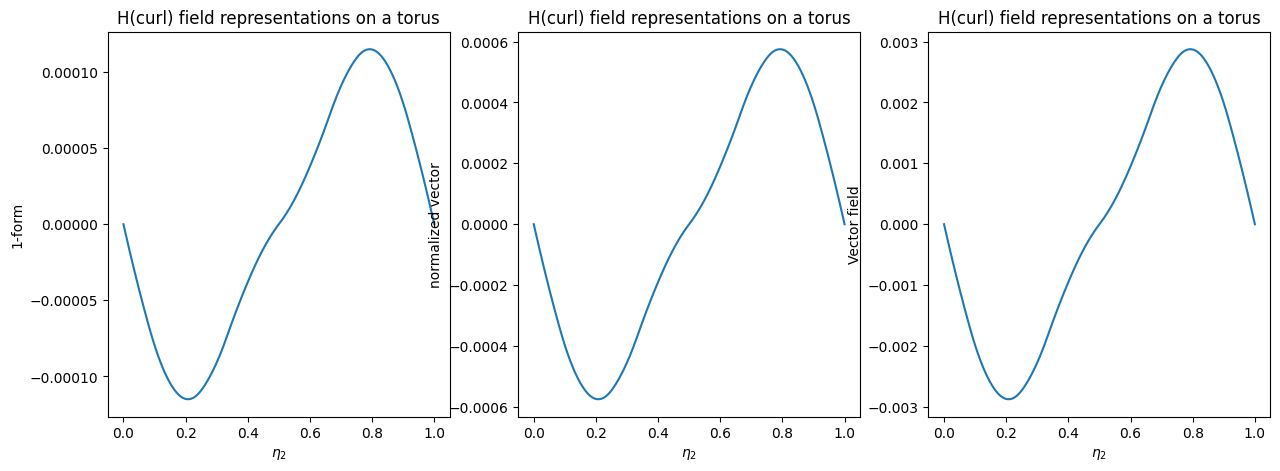

In [42]:
eta2_line = np.linspace(0.0, 1.0, 256)
component = 0
common = dict(eta1=0.7, eta2=eta2_line, eta3=0.0, t=-1, component=component)
e_1 = out_torus.evaluate("em_fields/e_field", representation="1", **common)
e_norm = out_torus.evaluate("em_fields/e_field", representation="norm", **common)
e_v = out_torus.evaluate("em_fields/e_field", representation="v", **common)

fig, ax = plt.subplots(ncols=3, figsize=(15, 5))
i = 0
for field, label in ((e_1, "1-form"), (e_norm, "normalized vector"), (e_v, "Vector field")):
    print(label, field)
    ax[i].plot(eta2_line, field, label=label)

    ax[i].set(xlabel=r"$\eta_2$", ylabel=label, title="H(curl) field representations on a torus")
    i += 1
# ax.legend()

## Apply the workflow to another run

For an already completed simulation, possibly in a separate process without MPI, open its output folder:

```python
import struphy

out = struphy.Output("/path/to/sim_1").pproc(physical=True)
out.domain, out.model.units  # reconstructed directly from saved metadata
```

Use `out.scalars`, `out.fields`, `out.distributions`, `out.orbits`, and `out.densities`. Attribute access is the normal interactive API; the corresponding `*_catalog` mappings are intended for generic loops and tooling.